In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Analysis saved to: ../data/analysis_F_values.csv
Summary Statistics:
            count       mean       std     min      25%     50%      75%  \
Min F      4783.0   3.306072  0.456302   2.567   2.9195   3.245   3.6540   
Max F      4783.0  17.424945  3.281998  12.216  14.6450  16.959  19.9010   
Range F    4783.0  14.118873  2.825747   9.649  11.7270  13.716  16.2495   
Average F  4783.0   7.311189  1.226801   5.376   6.2665   7.143   8.2485   

              max  
Min F       4.440  
Max F      25.741  
Range F    21.301  
Average F  10.223  

Top 5 Weight Combinations by Average F:
                                   Weights  Min F   Max F  Range F  Average F
0    w1, 0.35, w2, 0.23, w3, 0.22, w4, 0.2  4.440  25.741   21.301     10.223
1    w1, 0.35, w2, 0.24, w3, 0.21, w4, 0.2  4.436  25.721   21.285     10.217
2   w1, 0.35, w2, 0.24, w3, 0.22, w4, 0.19  4.420  25.580   21.160     10.183
4   w1, 0.35, w2, 0.25, w3, 0.21, w4, 0.19  4.416  25.560   21.144     10.177
13   w1, 0.35, w2, 

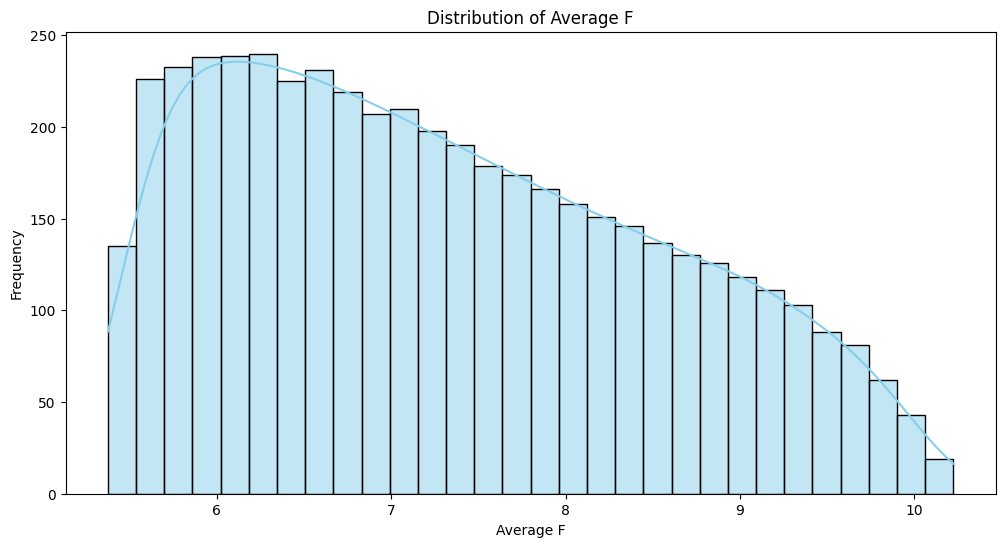

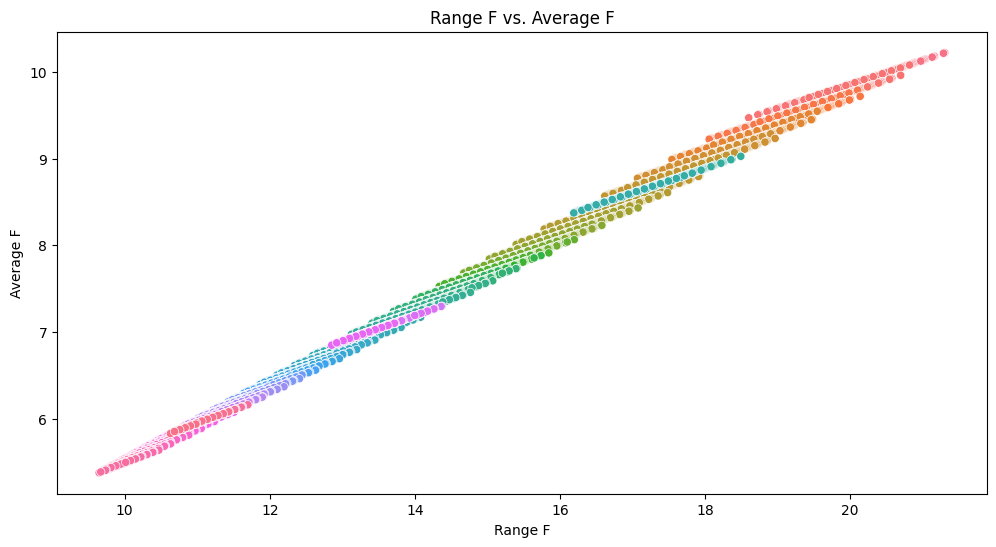

In [2]:
# Function to analyze `F` values across CSV files
def analyze_f_values(folder_path):
    """
    Analyze the `F` values across all CSV files in a given folder.
    
    Parameters:
    - folder_path: Path to the folder containing the CSV files.
    
    Returns:
    - DataFrame with the analysis of `F` values (min, max, range, average) for each file.
    """
    results = []
    
    for file_name in os.listdir(folder_path):
        if file_name.endswith('.csv'):  # Only process CSV files
            file_path = os.path.join(folder_path, file_name)
            
            data = pd.read_csv(file_path)
            
            # Calculate statistics for F
            min_f = data['F'].min()
            max_f = data['F'].max()
            range_f = max_f - min_f
            avg_f = round(data['F'].mean(), 3)
            
            weights = file_name.replace("results_", "").replace(".csv", "").replace("_", ", ")
            
            results.append({
                "Weights": weights,
                "Min F": min_f,
                "Max F": max_f,
                "Range F": range_f,
                "Average F": avg_f
            })
    
    result_df = pd.DataFrame(results)
    return result_df

folder_path = "../data/weight_combinations_results"
analysis_df = analyze_f_values(folder_path)

output_path = "../../../data/votable_supply-dhruvi/data/analysis_f_values.csv"
analysis_df.to_csv(output_path, index=False)
print(f"Analysis saved to: {output_path}")

data = pd.read_csv("../../../data/votable_supply-dhruvi/data/analysis_f_values.csv")

# 1. Basic Statistical Summary
summary = data.describe().T
print("Summary Statistics:")
print(summary)

# 2. Analyze Weight Combinations with Highest/Lowest Average F
top_average_f = data.nlargest(5, 'Average F')
lowest_average_f = data.nsmallest(5, 'Average F')

print("\nTop 5 Weight Combinations by Average F:")
print(top_average_f)

print("\nLowest 5 Weight Combinations by Average F:")
print(lowest_average_f)

# 3. Correlation Analysis
correlation = data[['Min F', 'Max F', 'Range F', 'Average F']].corr()
print("\nCorrelation Matrix:")
print(correlation)

# 4. Outlier Detection for Range F
q1 = data['Range F'].quantile(0.25)
q3 = data['Range F'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = data[(data['Range F'] < lower_bound) | (data['Range F'] > upper_bound)]
print("\nOutliers in Range F:")
print(outliers)

# 5. Visualizations
# Distribution of Average F
plt.figure(figsize=(12, 6))
sns.histplot(data['Average F'], kde=True, bins=30, color='skyblue')
plt.title('Distribution of Average F')
plt.xlabel('Average F')
plt.ylabel('Frequency')
plt.show()

# Scatter plot: Range F vs. Average F
plt.figure(figsize=(12, 6))
sns.scatterplot(data=data, x='Range F', y='Average F', hue='Weights', legend=None)
plt.title('Range F vs. Average F')
plt.xlabel('Range F')
plt.ylabel('Average F')
plt.show()
